# A Mixture of Experts

This tutorial
introduces a model with twelve parameters that has the same structure as the
constitutive-model surrogate: a **mixture of experts** (MoE), where a gating
network decides which expert is responsible for which part of the input
space.

The data contain a jump. We first show that a single smooth model cannot fit
them, and that a mixture of two small experts can. We then ask how well each
variational family describes the mixture's posterior:

* the Laplace approximation (a Gaussian fitted to the curvature at the MAP),
* `IIDGaussianGroup` (mean-field Gaussian),
* `LowRankGaussianGroup` (low-rank plus diagonal covariance), for every rank,
* `GaussianGroup` (full-covariance Gaussian),
* `LangevinGroup` (a trained Langevin sampler, with no fixed shape).

Twelve parameters are too many for a grid, so the reference posterior comes
from a long Hamiltonian Monte Carlo (HMC) run instead.

## Setup

In [1]:
import math
import pathlib
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch.optim.lr_scheduler import OneCycleLR

from pypolymix import StochasticModel, elbo_loss
from pypolymix.likelihoods import GaussianLikelihood
from pypolymix.parameter_groups import (GaussianGroup, IIDGaussianGroup, KNNEntropyKL, LangevinGroup,
                                        LowRankGaussianGroup)
from pypolymix.parameter_groups.kl_estimators import _knn_entropy
from pypolymix.priors import GaussianPrior
from pypolymix.surrogate_models import (GatingNetwork, MixtureOfExperts, NeuralNetwork, PolynomialChaosExpansion,
                                        SurrogateModel)

for _candidate in [pathlib.Path("docs/examples"), pathlib.Path(".")]:
    if (_candidate / "_cache_utils.py").exists():
        sys.path.insert(0, str(_candidate))
        CACHE_DIR = _candidate / ".cache" / "moe_posterior"
        break
else:
    raise RuntimeError("Could not locate _cache_utils.py -- run from the repo root or docs/examples/.")
from _cache_utils import CacheDir

cache = CacheDir(CACHE_DIR)
torch.set_default_dtype(torch.float64)
LOG2PI = math.log(2 * math.pi)
COLORS = {"exact": "0.3", "laplace": "tab:purple", "iid": "tab:blue", "lowrank": "tab:orange",
          "full": "tab:green", "langevin": "tab:red"}
LABELS = {"exact": "Reference (HMC)", "laplace": "Laplace", "iid": "Mean-field Gaussian",
          "lowrank": "Low-rank Gaussian", "full": "Full-covariance Gaussian", "langevin": "Langevin"}

## The data

Fifty noisy observations of a function with a jump at $x = 0$,
$$y = \sin(\pi x) + \operatorname{sign}(x) + \varepsilon, \qquad \varepsilon \sim N(0, \sigma^2),\quad \sigma = 0.05,$$
with the inputs drawn uniformly on $[-1, 1]$. The noise level is assumed
known. Where exactly the jump is can only be resolved down to the gap between
the two observations closest to $x = 0$.

the jump lies between x = -0.0214 and x = +0.0085 (a gap of width 0.0300)


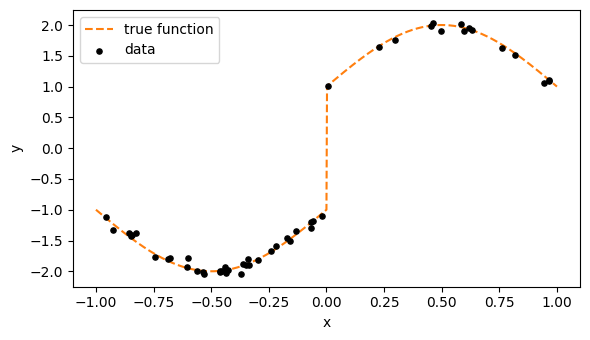

In [2]:
SIGMA = 0.05
N_TRAIN = 50
g = torch.Generator().manual_seed(1234)
x_train = 2 * torch.rand(N_TRAIN, 1, generator=g) - 1
y_train = torch.sin(torch.pi * x_train) + torch.sign(x_train) + SIGMA * torch.randn(x_train.shape, generator=g)

xs = x_train[:, 0]
GAP = (xs[xs < 0].max().item(), xs[xs > 0].min().item())
print(f"the jump lies between x = {GAP[0]:+.4f} and x = {GAP[1]:+.4f} (a gap of width {GAP[1] - GAP[0]:.4f})")

x_plot = torch.linspace(-1, 1, 801)[:, None]
f_true = torch.sin(torch.pi * x_plot[:, 0]) + torch.sign(x_plot[:, 0])

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(x_plot[:, 0], f_true, "--", color="tab:orange", label="true function")
ax.scatter(xs, y_train[:, 0], color="k", s=14, zorder=5, label="data")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
plt.tight_layout()

## Why a mixture?

First, a single smooth model with the same number of parameters: a Legendre
polynomial chaos expansion of degree 11 (twelve coefficients) with the prior
$N(0, 3^2)$ on every coefficient. This model is linear in its coefficients,
so with Gaussian noise and a Gaussian prior the posterior is exactly Gaussian
and available in closed form. So is the evidence
$\log p(y) = \log N\big(y;\, 0,\ \sigma^2 I + 3^2\,\Phi\Phi^\top\big)$, where
$\Phi$ holds the basis functions evaluated at the data.

single PCE (degree 11): log evidence = -442.6,  residual RMSE = 0.221 = 4.4 sigma
single PCE (degree 15): log evidence = -373.2
single PCE (degree 25): log evidence = -180.2


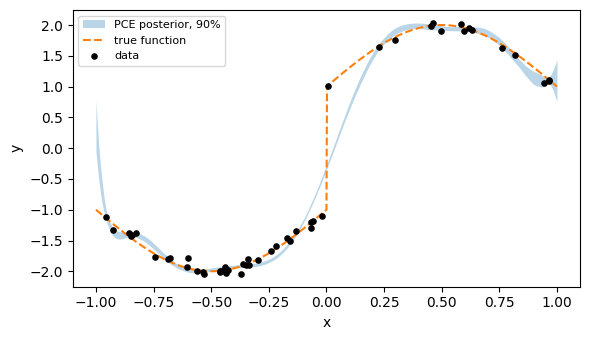

In [3]:
EXPERT_PRIOR_STD = 3.0


def pce_basis(degree, x):
    # (N, degree + 1) matrix of Legendre basis functions: evaluate the PCE with identity coefficients
    pce = PolynomialChaosExpansion(num_inputs=1, num_outputs=1, degree=degree)
    return pce(x, torch.eye(degree + 1))[:, :, 0].T


def pce_posterior(degree):
    Phi = pce_basis(degree, x_train)
    precision = Phi.T @ Phi / SIGMA**2 + torch.eye(degree + 1) / EXPERT_PRIOR_STD**2
    cov = torch.linalg.inv(precision)
    mean = cov @ Phi.T @ y_train[:, 0] / SIGMA**2
    evidence_cov = SIGMA**2 * torch.eye(N_TRAIN) + EXPERT_PRIOR_STD**2 * Phi @ Phi.T
    log_evidence = torch.distributions.MultivariateNormal(torch.zeros(N_TRAIN), evidence_cov).log_prob(y_train[:, 0])
    return mean, cov, log_evidence.item()


pce_mean, pce_cov, pce_log_evidence = pce_posterior(11)
rmse = ((pce_basis(11, x_train) @ pce_mean - y_train[:, 0]) ** 2).mean().sqrt().item()
print(f"single PCE (degree 11): log evidence = {pce_log_evidence:.1f},  residual RMSE = {rmse:.3f} = {rmse / SIGMA:.1f} sigma")
for degree in [15, 25]:
    print(f"single PCE (degree {degree}): log evidence = {pce_posterior(degree)[2]:.1f}")

draws = torch.distributions.MultivariateNormal(pce_mean, pce_cov).sample((200,))
f_pce = draws @ pce_basis(11, x_plot).T
band = torch.quantile(f_pce, torch.tensor([0.05, 0.95]), dim=0)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.fill_between(x_plot[:, 0], band[0], band[1], color="tab:blue", alpha=0.3, lw=0, label="PCE posterior, 90%")
ax.plot(x_plot[:, 0], f_true, "--", color="tab:orange", label="true function")
ax.scatter(xs, y_train[:, 0], color="k", s=14, zorder=5, label="data")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(fontsize=8)
plt.tight_layout()

The polynomial cannot bend fast enough at the jump. It overshoots on both
sides and rings across the whole interval, and its residuals are several
times the noise level. The posterior band is narrow nevertheless: the model is
confidently wrong, because a Gaussian posterior for a linear model only
reflects the noise and the prior, not the model's misfit. Raising the degree
helps only slowly. We compare these evidence values with the mixture's below.

## The mixture of experts

The mixture blends two cubic PCE experts $f_1, f_2$ with weights from a
softmax gate,
$$f(x;\theta) = \pi_1(x)\, f_1(x) + \pi_2(x)\, f_2(x),\qquad
\big(\pi_1(x), \pi_2(x)\big) = \operatorname{softmax}\big(w_1 x + b_1,\ w_2 x + b_2\big).$$
`GatingNetwork` with `depth=0` is exactly this linear gate. Together with the
four coefficients per expert, the model has twelve parameters, ordered as
`[expert 1 | expert 2 | w1, w2 | b1, b2]`.

Only the *difference* of the two logits matters, so the gate is a logistic
function of $x$ with slope $w_1 - w_2$ that switches at
$$x^\ast = -\frac{b_1 - b_2}{w_1 - w_2}.$$
Two consequences:

* **Two directions are set by the prior alone.** Adding the same constant to
  $w_1$ and $w_2$ (or to $b_1$ and $b_2$) changes nothing in the fit.
* **The posterior has two mirror-image modes.** Swapping the two experts
  (and their gate parameters) gives an identical fit. The modes are far apart,
  and every method below finds one of them. We map all results to the mode
  with $w_1 > w_2$ and compare against that mode alone. For any single-mode
  approximation, the KL to the full two-mode posterior is the number we report
  plus $\log 2$.

**Given the gate, the model is linear in the expert coefficients.** With
Gaussian noise and a Gaussian prior, their conditional posterior is then
exactly Gaussian. All the
non-Gaussianity comes through the gate.

In [4]:
D = 12
NAMES = [f"expert 1, c{i}" for i in range(4)] + [f"expert 2, c{i}" for i in range(4)] + ["w1", "w2", "b1", "b2"]
surrogate = MixtureOfExperts(
    experts=[PolynomialChaosExpansion(1, 1, degree=3), PolynomialChaosExpansion(1, 1, degree=3)],
    gating_network=GatingNetwork(num_inputs=1, num_experts=2, depth=0),
)
assert surrogate.num_params() == D


def canonicalize(theta):
    # map every row to the mode with w1 > w2 by swapping the expert labels (an exact symmetry)
    swap = (theta[..., 8] - theta[..., 9]) < 0
    t = theta.clone()
    s = t[swap]
    t[swap] = torch.cat([s[:, 4:8], s[:, 0:4], s[:, 9:10], s[:, 8:9], s[:, 11:12], s[:, 10:11]], 1)
    return t


def switch_location(theta):
    return -(theta[..., 10] - theta[..., 11]) / (theta[..., 8] - theta[..., 9])


def gate_slope(theta):
    return theta[..., 8] - theta[..., 9]

## The prior and the exact log posterior

Expert coefficients get the prior $N(0, 3^2)$, as for the single PCE. The
gate needs a much broader prior. To switch inside a gap of width 0.03, the
logit difference has to change by several units over that distance, so the
slope $w_1 - w_2$ must be in the hundreds. We use $N(0, 100^2)$ for the gate
parameters.

The data bound the gate's slope from below only: once the gate switches fully
inside the gap, a sharper gate fits the data just as well. How sharp the gate
can get is therefore decided by the prior, and so is the length of a ridge in
the posterior that we will meet below. With a narrower gate prior, std 30, the
prior cuts the ridge short and the posterior is much closer to Gaussian: a
full-covariance Gaussian then comes within 0.15 nats of it (measured
separately, not in this notebook).

With known noise, the unnormalized log posterior is
$$\log p(y, \theta) = -\sum_{i=1}^{N} \frac{(y_i - f(x_i;\theta))^2}{2\sigma^2}
- \sum_{j=1}^{12} \frac{\theta_j^2}{2 s_j^2} + \text{const},$$
with $s_j = 3$ for the experts and $s_j = 100$ for the gate. Every
variational family below uses the same prior, as a pypolymix `GaussianPrior`.

In [5]:
GATE_PRIOR_STD = 100.0
PRIOR_STD = torch.tensor([EXPERT_PRIOR_STD] * 8 + [GATE_PRIOR_STD] * 4)
prior = GaussianPrior(torch.zeros(D), covariance_matrix=torch.diag(PRIOR_STD**2))


def log_joint(theta):
    # log p(y | theta) + log p(theta) for a batch of parameter vectors, (S, 12) -> (S,)
    f = surrogate(x_train, theta)
    log_lik = -0.5 * ((y_train[None] - f) ** 2).sum((-1, -2)) / SIGMA**2 - N_TRAIN * (math.log(SIGMA) + 0.5 * LOG2PI)
    log_prior = -0.5 * ((theta / PRIOR_STD) ** 2).sum(-1) - (PRIOR_STD.log().sum() + 0.5 * D * LOG2PI)
    return log_lik + log_prior


def log_joint_chunked(theta, chunk=50_000):
    with torch.no_grad():
        return torch.cat([log_joint(c) for c in theta.split(chunk)])

## A deterministic fit first: the MAP

Every approximation starts at the posterior mode. For a mixture, finding it
takes some care, for two reasons:

* **Local optima.** From a random start, one expert can take over all the
  data while the gate stays flat. We therefore start from 64 random points and
  keep the best fit.
* **Parameter scales that differ by two orders of magnitude.** The gate parameters need values in
  the hundreds, the expert coefficients are of order one. Adam moves every
  parameter by roughly its learning rate per step, so a single learning rate
  is either too small for the gate or too large for the experts. We give the
  gate its own, larger learning rate, and finish with L-BFGS.

All 64 starts are optimized together: the surrogate is vectorized over
parameter rows, and the summed objective does not couple them.

In [6]:
N_STARTS, ADAM_STEPS = 64, 2000
g = torch.Generator().manual_seed(0)
theta_start = torch.randn(N_STARTS, D, generator=g)
theta_start[:, 8:] *= 3.0
experts_ = theta_start[:, :8].clone().requires_grad_(True)
gate_ = theta_start[:, 8:].clone().requires_grad_(True)
opt = torch.optim.Adam([{"params": [experts_], "lr": 0.05}, {"params": [gate_], "lr": 2.0}])
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, ADAM_STEPS)
for _ in range(ADAM_STEPS):
    opt.zero_grad()
    (-log_joint(torch.cat([experts_, gate_], 1))).sum().backward()
    opt.step()
    sched.step()

theta_all = torch.cat([experts_, gate_], 1).detach().requires_grad_(True)
lbfgs = torch.optim.LBFGS([theta_all], lr=1.0, max_iter=2000, tolerance_grad=1e-10, tolerance_change=1e-14,
                          history_size=50, line_search_fn="strong_wolfe")


def closure():
    lbfgs.zero_grad()
    loss = (-log_joint(theta_all)).sum()
    loss.backward()
    return loss


lbfgs.step(closure)
theta_all = canonicalize(theta_all.detach())
with torch.no_grad():
    lj_all = log_joint(theta_all)
    rmse_all = ((surrogate(x_train, theta_all) - y_train[None]) ** 2).mean((-1, -2)).sqrt()
theta_map = theta_all[lj_all.argmax()]
print(f"starts that split the data (RMSE < 3 sigma): {(rmse_all < 3 * SIGMA).float().mean().item():.0%}")
print(f"starts within 1 nat of the best:              {(lj_all > lj_all.max() - 1).float().mean().item():.0%}")
print(f"MAP: residual RMSE = {rmse_all.min().item():.4f},  gate slope w1 - w2 = {gate_slope(theta_map).item():.1f},  "
      f"switch at x* = {switch_location(theta_map).item():+.4f}")

starts that split the data (RMSE < 3 sigma): 66%
starts within 1 nat of the best:              61%
MAP: residual RMSE = 0.0575,  gate slope w1 - w2 = 261.1,  switch at x* = -0.0030


The **Laplace approximation** fits a Gaussian to the curvature at the MAP:
mean $\theta_{\text{MAP}}$, covariance the inverse Hessian of
$-\log p(y, \theta)$ there. We use it twice, as the starting covariance of
every variational family and of the HMC sampler, and we judge it as an
approximation in its own right further down.

Laplace standard deviations:
  expert 1, c0      0.5613
  expert 1, c1      1.1801
  expert 1, c2      0.9194
  expert 1, c3      0.3215
  expert 2, c0      0.2803
  expert 2, c1      0.6112
  expert 2, c2      0.5071
  expert 2, c3      0.2094
  w1               75.9426
  w2               75.9426
  b1               70.7123
  b2               70.7123


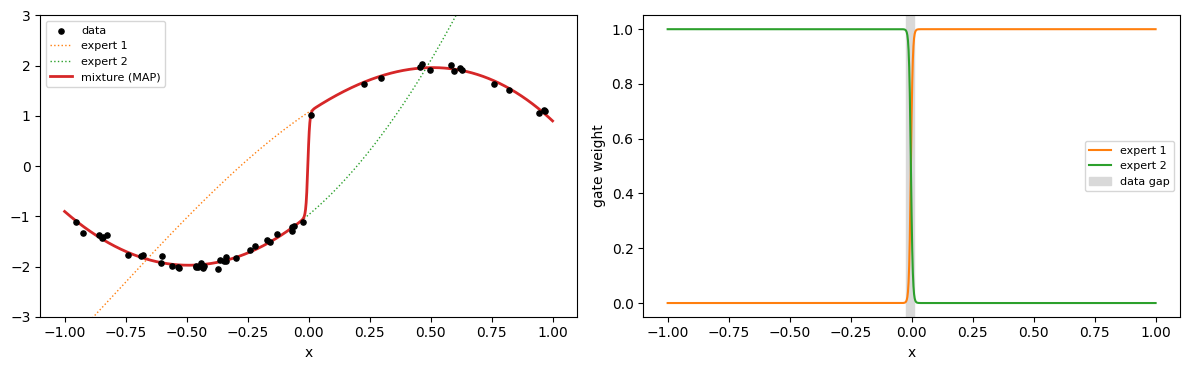

In [7]:
hessian = torch.autograd.functional.hessian(lambda t: -log_joint(t[None])[0], theta_map)
cov_laplace = torch.linalg.inv(hessian)
cov_laplace = 0.5 * (cov_laplace + cov_laplace.T)
print("Laplace standard deviations:")
for name, sd in zip(NAMES, cov_laplace.diagonal().sqrt()):
    print(f"  {name:14s} {sd.item():9.4f}")

with torch.no_grad():
    gates = surrogate.get_gating_weights(x_plot, theta_map[None])[0]
    experts = surrogate.get_expert_outputs(x_plot, theta_map[None])[0, :, :, 0]
    f_map = surrogate(x_plot, theta_map[None])[0, :, 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter(xs, y_train[:, 0], color="k", s=14, zorder=5, label="data")
for e in range(2):
    axes[0].plot(x_plot[:, 0], experts[e], color=f"C{e + 1}", lw=1, ls=":", label=f"expert {e + 1}")
axes[0].plot(x_plot[:, 0], f_map, color="tab:red", lw=2, label="mixture (MAP)")
axes[0].set_ylim(-3, 3)
axes[0].set_xlabel("x")
axes[0].legend(fontsize=8)
for e in range(2):
    axes[1].plot(x_plot[:, 0], gates[:, e], color=f"C{e + 1}", label=f"expert {e + 1}")
axes[1].axvspan(*GAP, color="0.85", label="data gap")
axes[1].set_xlabel("x")
axes[1].set_ylabel("gate weight")
axes[1].legend(fontsize=8)
plt.tight_layout()

Each expert is a cubic fitted to half of the data. Outside its own half it is
unconstrained, which is why the dotted curves wander off: that part of each
expert never reaches the output, because the gate switches it off.

## The reference posterior: Hamiltonian Monte Carlo

With twelve parameters a grid is out of the question, so the reference comes
from HMC. The sampler below is short enough to write out in full. All chains
are advanced together as one batch, so the log density is evaluated on a
`(num_chains, 12)` tensor, exactly as for the variational families.

* **Mass matrix.** A dense mass matrix makes HMC insensitive to correlations
  and to parameter scales. It starts from the Laplace covariance and is
  re-estimated from the chains three times during warmup.
* **Step size.** Dual averaging adapts the step size towards an acceptance
  rate of 0.8 (Hoffman & Gelman, "The No-U-Turn Sampler," JMLR 2014,
  Sec. 3.2), restarting after every mass-matrix update.
* **Trajectory length.** The number of leapfrog steps is drawn uniformly
  between $L/2$ and $L$ in every iteration, and the step size is jittered by
  20%, so that no trajectory is exactly periodic.
* **Diagnostics.** The split $\hat R$ is close to 1 when all chains agree,
  and the effective sample size (ESS) counts how many independent draws the
  correlated chains are worth (Gelman et al., *Bayesian Data Analysis*, 3rd
  ed., Sec. 11.4-11.5).

In [8]:
def _value_and_grad(log_prob, theta):
    theta = theta.detach().requires_grad_(True)
    lp = log_prob(theta)
    (g,) = torch.autograd.grad(lp.sum(), theta)
    return lp.detach(), g


def hmc(log_prob, theta0, *, num_warmup, num_samples, num_leapfrog, cov0, target_accept=0.8,
        mass_updates=(0.15, 0.3, 0.55), seed=0):
    # HMC from theta0 (one row per chain); returns samples of shape (num_samples, num_chains, dim)
    g = torch.Generator().manual_seed(seed)
    C, D_ = theta0.shape
    theta = theta0.clone()
    lp, grad = _value_and_grad(log_prob, theta)
    cov = cov0.clone()
    chol = torch.linalg.cholesky(cov)  # momentum p ~ N(0, cov^{-1}), velocity = cov p

    log_eps, log_eps_bar, hbar = math.log(0.1), 0.0, 0.0
    mu, t0, gamma, kappa = math.log(1.0), 10.0, 0.05, 0.75
    update_at = {int(f * num_warmup) for f in mass_updates}
    window, m_it = [], 0
    out = torch.empty(num_samples, C, D_)
    accept_rates = []
    for it in range(num_warmup + num_samples):
        warm = it < num_warmup
        eps = math.exp(log_eps if warm else log_eps_bar) * (0.8 + 0.4 * torch.rand(1, generator=g).item())
        n_lf = int(torch.randint(num_leapfrog // 2, num_leapfrog + 1, (1,), generator=g).item())

        # leapfrog integration of all chains at once
        xi = torch.randn(C, D_, generator=g)
        p = torch.linalg.solve_triangular(chol.T, xi.T, upper=True).T
        q, gq = theta, grad
        p = p + 0.5 * eps * gq
        for k in range(n_lf):
            q = q + eps * p @ cov
            lpq, gq = _value_and_grad(log_prob, q)
            if k < n_lf - 1:
                p = p + eps * gq
        p = p + 0.5 * eps * gq

        # Metropolis correction
        log_ratio = (lpq - 0.5 * ((p @ cov) * p).sum(-1)) - (lp - 0.5 * (xi**2).sum(-1))
        acc = torch.nan_to_num(log_ratio, nan=-math.inf).clamp(max=0).exp()
        accept = torch.rand(C, generator=g) < acc
        theta = torch.where(accept[:, None], q, theta)
        lp = torch.where(accept, lpq, lp)
        grad = torch.where(accept[:, None], gq, grad)
        a = acc.mean().item()

        if warm:  # dual averaging of the step size, periodic mass-matrix updates
            m_it += 1
            hbar = (1 - 1 / (m_it + t0)) * hbar + (target_accept - a) / (m_it + t0)
            log_eps = mu - math.sqrt(m_it) / gamma * hbar
            eta = m_it ** (-kappa)
            log_eps_bar = eta * log_eps + (1 - eta) * log_eps_bar
            window.append(theta.clone())
            if (it + 1) in update_at and len(window) > 10:
                w = torch.cat(window[len(window) // 2:], 0)
                emp, n = torch.cov(w.T), w.shape[0]
                cov = (n / (n + 5)) * emp + 1e-6 * (5 / (n + 5)) * torch.diag(emp.diagonal())
                chol = torch.linalg.cholesky(cov)
                window, m_it = [], 0
                mu, hbar, log_eps_bar = log_eps + math.log(2.0), 0.0, 0.0
        else:
            out[it - num_warmup] = theta
            accept_rates.append(a)
    return out, dict(step_size=math.exp(log_eps_bar), accept=sum(accept_rates) / len(accept_rates))


def rhat_ess(samples):
    # split R-hat and Geyer ESS for one scalar, samples of shape (num_samples, num_chains)
    n_half = samples.shape[0] // 2
    x = torch.cat([samples[:n_half], samples[n_half:2 * n_half]], 1).T  # (2C, n_half)
    m_, n = x.shape
    W = x.var(1).mean()
    rhat = (((n - 1) / n * W + x.mean(1).var()) / W).sqrt().item()
    xc = x - x.mean(1, keepdim=True)
    f = torch.fft.rfft(xc, n=2 * n)
    ac = torch.fft.irfft(f * f.conj(), n=2 * n)[:, :n]
    rho = (ac / ac[:, :1]).mean(0)
    tau = 1.0
    for t in range(1, n - 1, 2):
        pair = rho[t] + rho[t + 1]
        if pair < 0:
            break
        tau += 2 * pair
    return rhat, float(m_ * n / tau)

We run 32 chains for 1000 warmup and 4000 sampling iterations, starting near
the MAP in the $w_1 > w_2$ mode, and check that none of them crosses to the
mirror mode. One run takes about 90 seconds and is cached. Convergence is
checked for every parameter, and for the two gate quantities that matter
most: the switch location $x^\ast$ and the log of the gate slope.

In [9]:
def _run_hmc():
    g = torch.Generator().manual_seed(1)
    theta0 = theta_map + 0.5 * torch.randn(32, D, generator=g) @ torch.linalg.cholesky(cov_laplace).T
    t0 = time.time()
    samples, info = hmc(log_joint, theta0, num_warmup=1000, num_samples=4000, num_leapfrog=20, cov0=cov_laplace)
    return dict(samples=samples, step_size=info["step_size"], accept=info["accept"], time=time.time() - t0)


run = cache.get("hmc_v1", _run_hmc)
hmc_samples = run["samples"]  # (4000, 32, 12)
print(f"HMC: {run['time']:.0f}s, step size {run['step_size']:.3f}, acceptance {run['accept']:.2f}, "
      f"draws in the mirror mode: {(gate_slope(hmc_samples) < 0).sum().item()}")

checks = {name: hmc_samples[..., j] for j, name in enumerate(NAMES)}
checks["x*"] = switch_location(hmc_samples)
checks["log(w1 - w2)"] = gate_slope(hmc_samples).log()
print(f"{'':14s} {'mean':>9s} {'sd':>9s} {'R-hat':>7s} {'ESS':>8s}")
for name, v in checks.items():
    r, e = rhat_ess(v)
    print(f"{name:14s} {v.mean().item():9.4f} {v.std().item():9.4f} {r:7.3f} {e:8.0f}")

theta_exact = hmc_samples.reshape(-1, D)
# thinned and de-duplicated copy for nearest-neighbour estimates (rejected proposals repeat the previous draw)
theta_exact_knn = torch.unique(hmc_samples[::8].reshape(-1, D), dim=0)

[cache hit]  hmc_v1  <-  hmc_v1.pt
HMC: 97s, step size 0.223, acceptance 0.79, draws in the mirror mode: 0
                    mean        sd   R-hat      ESS
expert 1, c0      0.1996    0.4901   1.001    27949
expert 1, c1      2.7821    1.0378   1.001    29081
expert 1, c2     -1.7222    0.8216   1.001    32255
expert 1, c3     -0.3579    0.2949   1.001    39286
expert 2, c0      0.4081    0.2780   1.000   128000
expert 2, c1      4.0717    0.6062   1.000   128000
expert 2, c2      2.7566    0.5031   1.000   128000
expert 2, c3     -0.0041    0.2078   1.000   128000
w1              160.4877   79.6126   1.000   128000
w2             -160.2709   79.5639   1.000   128000
b1                0.5707   70.7715   1.000   128000
b2               -0.6208   70.7715   1.000   128000
x*               -0.0036    0.0035   1.001    34740
log(w1 - w2)      5.7465    0.2189   1.000    44926


### The normalizing constant

To report a KL divergence we need $\log Z = \log p(y)$. We estimate it by
importance sampling,
$$Z = \mathbb{E}_{r}\!\left[\frac{p(y, \theta)}{r(\theta)}\right],$$
with a proposal $r$ built from the HMC sample mean and covariance. We use two
different proposals, a heavy-tailed Student-$t$ and an inflated Gaussian; if
the two agree, the estimate can be trusted. With $\log Z$ in hand, the
entropy of the exact posterior follows from the HMC samples,
$H[p] = -\mathbb{E}_p[\log p(y, \theta)] + \log Z$.

In [10]:
mu_exact, cov_exact = theta_exact.mean(0), torch.cov(theta_exact.T)
g = torch.Generator().manual_seed(0)
n_is = 400_000
log_Z = {}
for name, df, inflate in [("Student-t (5 dof)", 5.0, 1.0), ("Gaussian, covariance x1.5", None, 1.5)]:
    L_r = torch.linalg.cholesky(inflate * cov_exact)
    eps = torch.randn(n_is, D, generator=g)
    if df is None:
        theta_r = mu_exact + eps @ L_r.T
        log_r = -0.5 * (eps**2).sum(1) - L_r.diagonal().log().sum() - 0.5 * D * LOG2PI
    else:
        scale = (df / torch.distributions.Chi2(df).sample((n_is,))).sqrt()
        theta_r = mu_exact + (eps * scale[:, None]) @ L_r.T
        log_r = (torch.lgamma(torch.tensor((df + D) / 2)) - torch.lgamma(torch.tensor(df / 2))
                 - 0.5 * D * math.log(df * math.pi) - L_r.diagonal().log().sum()
                 - 0.5 * (df + D) * torch.log1p((eps**2).sum(1) * scale**2 / df))
    log_w = log_joint_chunked(theta_r) - log_r
    log_Z[name] = (torch.logsumexp(log_w, 0) - math.log(n_is)).item()
    w = (log_w - log_w.max()).exp()
    print(f"log Z with a {name:26s}: {log_Z[name]:.3f}   (effective sample size {(w.sum()**2 / (w**2).sum()).item():.0f} of {n_is})")
logZ = log_Z["Student-t (5 dof)"]
H_exact = -(log_joint_chunked(theta_exact) - logZ).mean().item()
print(f"entropy of the exact posterior H[p] = {H_exact:.3f} nats")
print(f"\nlog evidence: mixture of experts {logZ:.1f}  vs  single PCE of degree 11 {pce_log_evidence:.1f}  "
      f"(log Bayes factor {logZ - pce_log_evidence:.0f})")

log Z with a Student-t (5 dof)         : 28.166   (effective sample size 94156 of 400000)


log Z with a Gaussian, covariance x1.5 : 28.174   (effective sample size 76698 of 400000)
entropy of the exact posterior H[p] = 6.410 nats

log evidence: mixture of experts 28.2  vs  single PCE of degree 11 -442.6  (log Bayes factor 471)


The evidence settles the question from the start of the tutorial: with the
same number of parameters, the data favour the mixture over the single
polynomial by hundreds of nats.

### What the posterior looks like

Most of the twelve dimensions are unremarkable: given the gate, the expert
coefficients are exactly Gaussian, if strongly correlated. The interesting part is the gate, shown below in the two quantities
that describe it: where it switches ($x^\ast$) and how sharply (the slope).

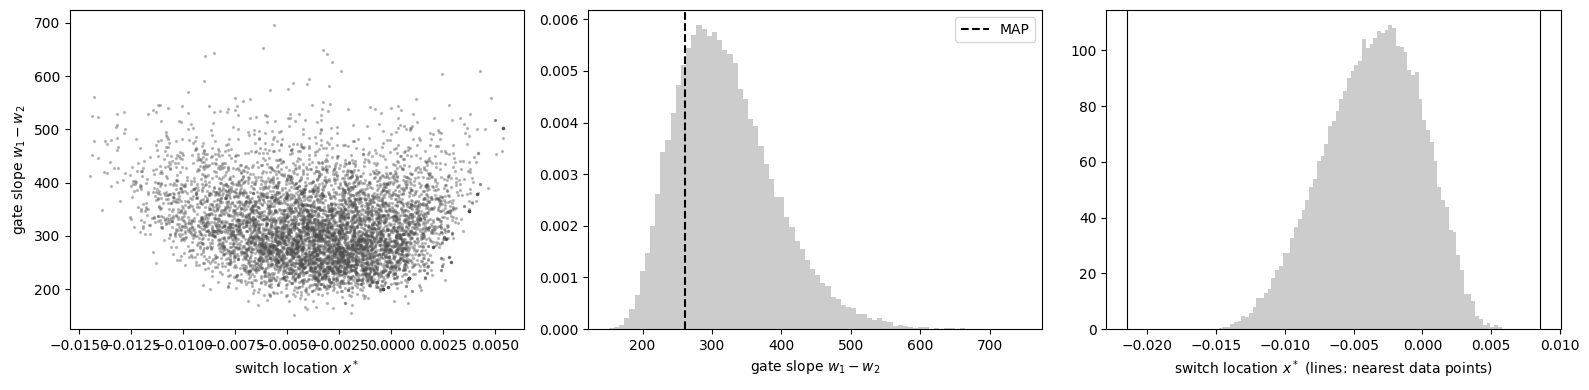

In [11]:
slope_exact, xstar_exact = gate_slope(theta_exact), switch_location(theta_exact)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(xstar_exact[::20], slope_exact[::20], s=2, alpha=0.3, color=COLORS["exact"])
axes[0].set_xlabel("switch location $x^*$")
axes[0].set_ylabel("gate slope $w_1 - w_2$")
axes[1].hist(slope_exact.numpy(), bins=80, density=True, color="0.8")
axes[1].axvline(gate_slope(theta_map).item(), color="k", ls="--", label="MAP")
axes[1].set_xlabel("gate slope $w_1 - w_2$")
axes[1].legend()
axes[2].hist(xstar_exact.numpy(), bins=80, density=True, color="0.8")
for x_ in GAP:
    axes[2].axvline(x_, color="k", lw=0.8)
axes[2].set_xlabel("switch location $x^*$ (lines: nearest data points)")
plt.tight_layout()

**A one-sided ridge.** The slope cannot be much smaller than at the MAP:
below that, the gate is still half-open at the nearest data points and the
fit degrades quickly. Above the MAP, the likelihood no longer cares, and only
the prior pulls the slope back. The result is a skewed distribution with the
MAP at its steep edge, not at its centre. The switch location stays inside
the data gap.

## The Laplace approximation

KL divergences between a Gaussian $q$ and the exact posterior are computed
exactly, up to Monte Carlo error: $\log q$ is known, $\log p(y, \theta)$ is
known, and $\log Z$ comes from above,
$$\mathrm{KL}(q\,\|\,p) = \mathbb{E}_q\big[\log q(\theta) - \log p(y, \theta)\big] + \log Z .$$

In [12]:
def exact_kl(q, n=200_000, seed=123):
    # KL(q || p(theta | y)) for a distribution q with a known log density
    torch.manual_seed(seed)
    with torch.no_grad():
        th = q.sample((n,))
        return (q.log_prob(th) - log_joint_chunked(th)).mean().item() + logZ


q_laplace = torch.distributions.MultivariateNormal(theta_map, covariance_matrix=cov_laplace)
kl_laplace = exact_kl(q_laplace)
print(f"Laplace: KL(q || p) = {kl_laplace:.3f} nats")
with torch.no_grad():
    theta_laplace = q_laplace.sample((200_000,))
for name, th in [("reference", theta_exact), ("Laplace", theta_laplace)]:
    qs = torch.quantile(gate_slope(th), torch.tensor([0.05, 0.5, 0.95]))
    print(f"  {name:9s}: gate slope 5/50/95% = {qs.numpy().round(0)}")

Laplace: KL(q || p) = 5.014 nats
  reference: gate slope 5/50/95% = [220. 312. 452.]
  Laplace  : gate slope 5/50/95% = [170. 261. 352.]


The Laplace approximation is centred on the MAP and symmetric around it, so
it misses the mass on the sharp side of the ridge. Its KL is large, even
though the rest of the posterior is close to Gaussian.

## Variational families

Every family is trained with the same loop: a
`StochasticModel` combines the surrogate with one parameter group over all
twelve parameters, and we minimize the negative ELBO from `elbo_loss`, with
the `GaussianLikelihood` noise frozen at its known value. Because the negative ELBO equals
$\mathrm{KL}(q\,\|\,p) - \log Z$ per data set,
$N \cdot \text{loss} + \log Z$ is a running estimate of the KL to the exact
posterior.

**Starting point.** A cold start (MAP mean, small isotropic spread) trains
slowly here: the posterior is about $10^{-2}$ wide in its thinnest
directions and about $10^{2}$ wide along the gate, and Adam needs thousands
of steps to cover that range. Every family therefore starts from
the Laplace approximation, projected onto the family:

* **mean-field:** variances $1 / \operatorname{diag}(H)$, the best diagonal
  Gaussian for a Gaussian target with precision $H$;
* **low-rank, rank $r$:** the same diagonal, plus the $r$ leading
  eigenvectors of what the diagonal leaves unexplained;
* **full:** the Cholesky factor of the Laplace covariance.

We fit the mean-field Gaussian, the low-rank Gaussian for every rank from 1
to 11, and the full-covariance Gaussian, each for 10,000 epochs.

**Three seeds per family.** The low-rank parameterization
$UU^\top + \operatorname{diag}(d)$ is harder to optimize than the other two:
at high ranks the final KL of a single run can be off by a few tenths of a
nat. We therefore train every family with three seeds and keep the run with
the lowest training loss over its last 500 epochs. This choice uses only
the ELBO, never the reference posterior. A fit takes about 45 seconds, so
all 39 fits take about half an hour, and they are cached.

In [13]:
likelihood = GaussianLikelihood(num_outputs=1, init_sigma=SIGMA).requires_grad_(False)  # known noise


def train(group, surr, *, num_epochs, num_samples, lr, max_lr_mult=1.0, clip=None, seed=0, on_epoch=None):
    torch.manual_seed(seed)
    model = StochasticModel(surr, group)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = OneCycleLR(optimizer, max_lr=max_lr_mult * lr, total_steps=num_epochs)
    history = np.zeros(num_epochs)
    for epoch in range(num_epochs):
        if on_epoch is not None:  # optional per-epoch hook, used by the Langevin group below
            on_epoch(epoch)
        optimizer.zero_grad()
        pred = model(x_train, num_samples=num_samples)
        loss = elbo_loss(likelihood.nll(pred, y_train), model.distribution_loss(), n_train=N_TRAIN)
        loss.backward()
        if clip is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        scheduler.step()
        history[epoch] = N_TRAIN * loss.item()  # negative ELBO in nats
    return history


def inverse_softplus(y):
    # numerically stable inverse of softplus, valid for large y (log(expm1(y)) overflows)
    return y + torch.log(-torch.expm1(-y))


D_MF = 1.0 / hessian.diagonal()  # mean-field variances: 1 / diag(H)


def make_group(rank, init=True, seed=0):
    # rank 0: mean-field, rank 1..11: low-rank plus diagonal, rank 12: full covariance
    torch.manual_seed(seed)
    if rank == 0:
        group = IIDGaussianGroup("theta", D, prior=prior)
        if init:
            with torch.no_grad():
                group.mean.copy_(theta_map)
                group.log_std.copy_(0.5 * D_MF.log())
    elif rank == D:
        group = GaussianGroup("theta", D, prior=prior)
        if init:
            L_lap = torch.linalg.cholesky(cov_laplace)
            with torch.no_grad():
                group.mean.copy_(theta_map)
                raw = L_lap[group._tri_i, group._tri_j].clone()
                on_diag = group._tri_i == group._tri_j
                raw[on_diag] = inverse_softplus((L_lap.diagonal() - group.min_scale).clamp_min(1e-12))
                group.raw_tril.copy_(raw)
    else:
        group = LowRankGaussianGroup("theta", D, rank, prior=prior)
        if init:
            evals, evecs = torch.linalg.eigh(cov_laplace - torch.diag(D_MF))
            U = evecs[:, -rank:] * evals[-rank:].clamp_min(0).sqrt()
            # columns that start at exactly zero never move (zero gradient of U U^T): small random start
            dead = U.norm(dim=0) < 1e-8
            U[:, dead] = 1e-2 * D_MF.sqrt()[:, None] * torch.randn(D, int(dead.sum()))
            with torch.no_grad():
                group.mean.copy_(theta_map)
                group.cov_factor.copy_(U)
                group.raw_cov_diag.copy_(inverse_softplus((D_MF - group.min_variance).clamp_min(1e-12)))
    return group


GAUSS_CFG = dict(num_epochs=10_000, num_samples=256, lr=1e-2, max_lr_mult=2.0)
GAUSS_SEEDS = [0, 1, 2]
RANKS = list(range(D + 1))


def gauss_key(rank, seed):
    return f"gauss_rank{rank}_v1" if seed == 0 else f"gauss_rank{rank}_seed{seed}_v1"


gauss = {}
print(f"{'':18s} {'KL, selected run':>17s}   KL of each seed")
for rank in RANKS:
    runs = []
    for seed in GAUSS_SEEDS:
        def _fit(rank=rank, seed=seed):
            group = make_group(rank, seed=seed)
            t0 = time.time()
            hist = train(group, surrogate, seed=seed, **GAUSS_CFG)
            return dict(state_dict=group.state_dict(), hist=hist, time=time.time() - t0)

        fit = cache.get(gauss_key(rank, seed), _fit)
        group = make_group(rank, init=False)
        group.load_state_dict(fit["state_dict"])
        runs.append(dict(fit, group=group, final_loss=fit["hist"][-500:].mean(),
                         kl=exact_kl(group.variational_distribution())))
    best = min(runs, key=lambda r: r["final_loss"])  # selected by the ELBO alone
    gauss[rank] = dict(best, all_kl=[r["kl"] for r in runs], runs=runs)
    label = "mean-field" if rank == 0 else ("full" if rank == D else f"low-rank, r = {rank}")
    print(f"{label:18s} {best['kl']:17.3f}   " + "  ".join(f"{k:.3f}" for k in gauss[rank]["all_kl"]))
kl_iid, kl_full = gauss[0]["kl"], gauss[D]["kl"]

                    KL, selected run   KL of each seed
[cache hit]  gauss_rank0_v1  <-  gauss_rank0_v1.pt


[cache miss] gauss_rank0_seed1_v1  ->  gauss_rank0_seed1_v1.pt  (computed in 45.2s)


[cache miss] gauss_rank0_seed2_v1  ->  gauss_rank0_seed2_v1.pt  (computed in 45.4s)
mean-field                    14.580   14.580  14.580  14.580
[cache hit]  gauss_rank1_v1  <-  gauss_rank1_v1.pt


[cache miss] gauss_rank1_seed1_v1  ->  gauss_rank1_seed1_v1.pt  (computed in 98.4s)


[cache miss] gauss_rank1_seed2_v1  ->  gauss_rank1_seed2_v1.pt  (computed in 100.7s)


low-rank, r = 1               10.065   10.162  10.065  10.112
[cache hit]  gauss_rank2_v1  <-  gauss_rank2_v1.pt


... (23 outputs left out)

low-rank, r = 11               0.658   0.670  0.779  0.658
[cache hit]  gauss_rank12_v1  <-  gauss_rank12_v1.pt


[cache hit]  gauss_rank12_seed1_v1  <-  gauss_rank12_seed1_v1.pt


[cache miss] gauss_rank12_seed2_v1  ->  gauss_rank12_seed2_v1.pt  (computed in 45.2s)


full                           0.552   0.555  0.552  0.552


## How much rank does the covariance need?

A full covariance matrix has $d(d+1)/2$ entries, which is affordable for
twelve parameters but not for the tens of thousands of a realistic surrogate.
A low-rank-plus-diagonal covariance has $d(r+1)$ entries. The question is how
small $r$ can be before the approximation suffers.

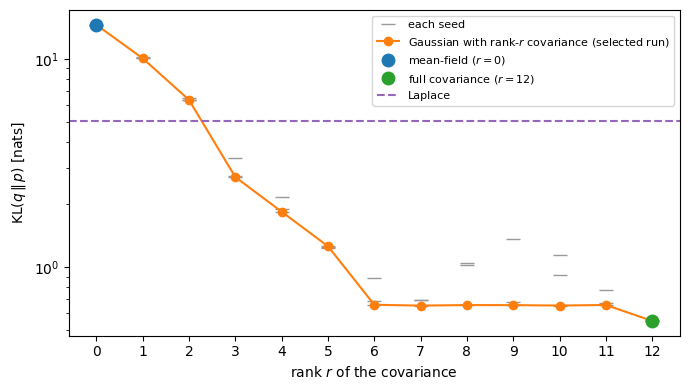

In [14]:
kl_rank = np.array([gauss[r]["kl"] for r in RANKS])
fig, ax = plt.subplots(figsize=(7, 4))
for r in RANKS:
    ax.plot([r] * len(GAUSS_SEEDS), gauss[r]["all_kl"], "_", color="0.6", ms=10, zorder=1)
ax.plot([], [], "_", color="0.6", ms=10, label="each seed")
ax.plot(RANKS, kl_rank, "o-", color=COLORS["lowrank"], label="Gaussian with rank-$r$ covariance (selected run)")
ax.plot([0], [kl_iid], "o", color=COLORS["iid"], ms=9, label="mean-field ($r = 0$)")
ax.plot([D], [kl_full], "o", color=COLORS["full"], ms=9, label=f"full covariance ($r = {D}$)")
ax.axhline(kl_laplace, color=COLORS["laplace"], ls="--", label="Laplace")
ax.set_yscale("log")
ax.set_xticks(RANKS)
ax.set_xlabel("rank $r$ of the covariance")
ax.set_ylabel(r"KL$(q\,\|\,p)$ [nats]")
ax.legend(fontsize=8)
plt.tight_layout()

The mean-field Gaussian is the worst approximation in this tutorial, with a
KL about three times that of the Laplace approximation. Each added rank
removes a large part of the gap. From rank 6 on, the curve is flat at about
0.65 nats for every seed, about 0.1 nats above the full-covariance Gaussian.
Even rank 11, which can represent any covariance matrix, stays at that level,
and a separate fit at rank 10 with three times as many epochs stopped at
0.64 nats. The last 0.1 nats are therefore an optimization effect of the
low-rank parameterization, not a matter of rank.

**Why rank 6?** The correlations a covariance has to capture can be read
from the reference itself. For a Gaussian target, the best mean-field
approximation has KL $-	frac12\sum_i \log\lambda_i$, where $\lambda_i$ are
the eigenvalues of the posterior *correlation* matrix: every eigenvalue far
below one marks a combination of parameters that the data pin down much more
tightly than any single parameter.

In [15]:
corr = torch.corrcoef(theta_exact.T)
lam, vecs = torch.linalg.eigh(corr)
print(f"{'eigenvalue':>11s} {'-log(lam)/2':>12s}   largest loadings")
for l_, v_ in zip(lam, vecs.T):
    top = sorted(zip(v_.abs().tolist(), NAMES), reverse=True)[:3]
    print(f"{l_.item():11.1e} {-0.5 * l_.log().item():12.2f}   " + ", ".join(f"{n} ({a:.2f})" for a, n in top))
print(f"corr(b1, b2) = {corr[10, 11].item():.4f}")

 eigenvalue  -log(lam)/2   largest loadings
    1.1e-04         4.58   b2 (0.71), b1 (0.71), expert 1, c0 (0.05)
    2.3e-04         4.18   expert 1, c1 (0.80), expert 1, c0 (0.53), expert 1, c2 (0.29)
    4.3e-04         3.88   expert 2, c1 (0.76), expert 2, c0 (0.64), expert 2, c3 (0.07)
    1.3e-03         3.32   expert 2, c2 (0.76), expert 1, c2 (0.39), expert 2, c0 (0.32)
    1.3e-03         3.31   expert 1, c2 (0.71), expert 1, c0 (0.41), expert 2, c2 (0.41)
    3.0e-02         1.75   expert 2, c3 (0.83), expert 2, c0 (0.46), expert 2, c1 (0.31)
    4.4e-02         1.56   expert 1, c3 (0.78), expert 1, c0 (0.50), expert 1, c1 (0.34)
    3.7e-01         0.50   w2 (0.70), w1 (0.70), expert 1, c3 (0.13)
    1.6e+00        -0.23   w1 (0.71), w2 (0.71), b2 (0.00)
    2.0e+00        -0.35   b2 (0.71), b1 (0.71), expert 2, c3 (0.01)
    3.9e+00        -0.69   expert 2, c2 (0.40), expert 2, c1 (0.40), expert 2, c0 (0.40)
    4.0e+00        -0.70   expert 1, c2 (0.40), expert 1, c1 (0.39)

Seven combinations stand out, with eigenvalues below 0.05, and together they
account for nearly all of the mean-field KL. One ties $b_1$ to $b_2$: each
offset on its own is set by the prior, but their difference fixes where the
gate switches. The other six tie together expert coefficients, mostly
within one expert. Each expert only sees half of the interval, so its four
coefficients are well determined in some combinations and poorly in others.
A diagonal covariance cannot represent any of these dependencies. In the
rank sweep above, rank 6 is enough to capture almost all of them.

## Langevin

For `LangevinGroup`, the dynamics run in
whitened coordinates $z$, with the fixed affine map $\theta = m + Lz$ taken
from a trained full-covariance Gaussian (the seed-0 run), and the prior
pushed through the same map. The particles therefore start out distributed as the full
Gaussian, and the score network only has to learn the correction. Training
backpropagates through all $K$ Langevin steps, with a random number of steps
$K$ between 200 and 400 per epoch, and `KNNEntropyKL` estimates the entropy
from the particles.

The step size follows two rules of thumb: the noise floor $\sqrt{2h}$ must
stay below the thinnest local width of the posterior in $z$, and $h$ must stay
below $2/\lambda$ for the stiffest local curvature $\lambda$.

In [16]:
precond = gauss[D]["runs"][0]  # seed-0 full Gaussian: fixed, so cached Langevin runs stay valid
q_precond = precond["group"].variational_distribution()
m, L = q_precond.mean.detach(), q_precond.scale_tril.detach()
Linv = torch.linalg.inv(L)
prior_z = GaussianPrior(-Linv @ m, covariance_matrix=Linv @ torch.diag(PRIOR_STD**2) @ Linv.T)


def z_to_theta(z):
    return m + z @ L.T


def theta_to_z(theta):
    return torch.linalg.solve_triangular(L, (theta - m).T, upper=False).T


class Affine(SurrogateModel):
    # evaluate the base surrogate at theta = m + L z
    num_inputs, num_outputs = 1, 1

    def __init__(self, base):
        super().__init__()
        self.base = base

    def forward(self, x, z):
        return self.base(x, z_to_theta(z))

    def num_params(self):
        return self.base.num_params()


z_probe = theta_to_z(theta_exact_knn[torch.randperm(theta_exact_knn.shape[0],
                                                     generator=torch.Generator().manual_seed(0))[:300]])
lam_max = torch.stack([
    torch.linalg.eigvalsh(torch.autograd.functional.hessian(lambda z: -log_joint(z_to_theta(z[None]))[0], z)).max()
    for z in z_probe
])
w05, lam99 = lam_max.rsqrt().quantile(0.05).item(), lam_max.quantile(0.99).item()
STEP = 1e-2
K_MIN, K_MAX = 200, 400
PARTICLES = 512  # particles per epoch; also the sample size of the kNN entropy estimate in training
print(f"thinnest 5%: local width w = {w05:.3f}   ->  noise floor  h <= w^2/2      = {w05**2 / 2:.4f}")
print(f"stiffest 1%: curvature   = {lam99:.1f}   ->  stability    h <  2/curvature = {2 / lam99:.4f}")
print(f"chosen: h = {STEP}, K between {K_MIN} and {K_MAX} steps, {PARTICLES} particles")


def make_langevin(seed):
    torch.manual_seed(seed)
    score = NeuralNetwork(num_inputs=D, num_outputs=D, width=64, depth=2, activation=F.tanh)
    return LangevinGroup("z", D, score_model=score, prior=prior_z, num_particles=PARTICLES,
                         num_diffusion_steps=K_MAX, step_size=STEP, init_std=1.0, kl_estimator=KNNEntropyKL(k=4))

thinnest 5%: local width w = 0.339   ->  noise floor  h <= w^2/2      = 0.0575
stiffest 1%: curvature   = 13.5   ->  stability    h <  2/curvature = 0.1486
chosen: h = 0.01, K between 200 and 400 steps, 512 particles


### Training

A $12 \to 64 \to 64 \to 12$ tanh score network, 3000 epochs at a learning
rate of $5\cdot10^{-3}$, with gradient clipping. One run takes about 20
minutes, so each run is cached. The seeds are set in the next cell, so they
can also be trained in parallel (for example with papermill, one seed per
process) and then collected from the cache.

In [17]:
SEEDS = [0, 1, 2]

In [18]:
LANGEVIN_CFG = dict(num_epochs=3000, num_samples=PARTICLES, lr=5e-3, clip=10.0)
langevin = {}
for seed in SEEDS:
    def _train(seed=seed):
        group = make_langevin(seed)
        rng = np.random.default_rng(seed)

        def random_horizon(epoch):
            group.num_diffusion_steps = int(rng.integers(K_MIN, K_MAX + 1))

        t0 = time.time()
        hist = train(group, Affine(surrogate), seed=seed, on_epoch=random_horizon, **LANGEVIN_CFG)
        group.num_diffusion_steps = K_MAX
        torch.manual_seed(1000 + seed)
        with torch.no_grad():
            z = group.sample_parameters(4000)
        return dict(state_dict=group.state_dict(), hist=hist, z=z, time=time.time() - t0)

    run = cache.get(f"langevin_p{PARTICLES}_seed{seed}_v1", _train)
    group = make_langevin(seed)
    group.load_state_dict(run["state_dict"])
    langevin[seed] = dict(run, group=group, theta=z_to_theta(run["z"]))

[cache hit]  langevin_p512_seed0_v1  <-  langevin_p512_seed0_v1.pt
[cache hit]  langevin_p512_seed1_v1  <-  langevin_p512_seed1_v1.pt
[cache hit]  langevin_p512_seed2_v1  <-  langevin_p512_seed2_v1.pt


### Measuring the KL without a density

Langevin has no density we can evaluate, so we split the KL as
$\mathrm{KL}(q\,\|\,p) = \mathbb{E}_q[-\log p(\theta\mid y)] - H[q]$, where
the first term is exact and the entropy $H[q]$ comes from the kNN estimator
on 4000 samples, in the whitened coordinates. In twelve dimensions the kNN
estimator is much more biased than in two, and the bias depends on the shape
of the distribution. We therefore correct it in two ways, each with a
reference whose KL we know:

* with 4000 exact posterior samples (from HMC, thinned and de-duplicated),
  whose entropy we know;
* with 4000 samples of the full-covariance Gaussian used as the preconditioner,
  whose KL we know exactly.

The two corrected values bracket the Langevin KL, and their difference is an
honest error bar for this estimate.

In [19]:
LOG_DET_L = L.diagonal().abs().log().sum().item()
N_EVAL = 4000


def knn_entropy(theta, k=4):
    return _knn_entropy(theta_to_z(theta), k=k).item() + LOG_DET_L


def kl_knn_raw(theta):
    with torch.no_grad():
        return -(log_joint(theta) - logZ).mean().item() - knn_entropy(theta)


idx = torch.randperm(theta_exact_knn.shape[0], generator=torch.Generator().manual_seed(1))[:N_EVAL]
bias_exact = kl_knn_raw(theta_exact_knn[idx]) - 0.0  # the exact posterior has KL 0
torch.manual_seed(2)
with torch.no_grad():
    theta_precond = q_precond.sample((N_EVAL,))
bias_full = kl_knn_raw(theta_precond) - precond["kl"]
print(f"kNN KL offset on exact samples:        {bias_exact:+.3f} nats")
print(f"kNN KL offset on the full Gaussian:    {bias_full:+.3f} nats")
for seed in SEEDS:
    raw = kl_knn_raw(langevin[seed]["theta"])
    langevin[seed]["kl"] = (raw - bias_exact, raw - bias_full)
    print(f"Langevin seed {seed}: KL(q || p) between {min(langevin[seed]['kl']):.3f} and {max(langevin[seed]['kl']):.3f} nats")
kl_lang = np.array([langevin[s]["kl"] for s in SEEDS])  # (seeds, 2 calibrations)
SHOW = SEEDS[int(np.argsort(kl_lang.mean(1))[len(SEEDS) // 2])]  # the median seed, used in the plots
print(f"mean over seeds: between {kl_lang.min(1).mean():.3f} and {kl_lang.max(1).mean():.3f} nats "
      f"(full-covariance Gaussian: {kl_full:.3f})")

kNN KL offset on exact samples:        -0.363 nats
kNN KL offset on the full Gaussian:    -0.162 nats
Langevin seed 0: KL(q || p) between 0.680 and 0.881 nats
Langevin seed 1: KL(q || p) between 0.600 and 0.801 nats


Langevin seed 2: KL(q || p) between 0.652 and 0.853 nats
mean over seeds: between 0.644 and 0.845 nats (full-covariance Gaussian: 0.552)


**Langevin does not beat the full-covariance Gaussian here.** Its KL is
close to that of the full Gaussian, and slightly above it, for every seed,
even though in the two-parameter examples (Exponential Decay and The
Rosenbrock Banana) it was several times lower. Is that a limit of the
dynamics, of the score network, or of the training?

### Is the network too small?

Two checks answer this without any training through the ELBO.

1. **Exact score.** Here we know $\log p(y, \theta)$, so we can run the same
   dynamics (same coordinates, step size, and starting distribution) with
   the exact score $\nabla_z \log p$ as the drift. If these particles reach
   the posterior, the dynamics are not the limit.
2. **The same network, fitted to the exact score.** We regress a score
   network of the same size ($12 \to 64 \to 64 \to 12$) onto the exact score,
   at points along the exact-score trajectories, and run the dynamics with
   it. If this network also reaches the posterior, its size is not the
   limit either.

In [20]:
def exact_score(z):
    zz = z.detach().requires_grad_(True)
    (s,) = torch.autograd.grad(log_joint(z_to_theta(zz)).sum(), zz)
    return s.detach()


def kl_bracket(theta):
    raw = kl_knn_raw(theta)
    return sorted((raw - bias_exact, raw - bias_full))


noise = math.sqrt(2 * STEP)
g = torch.Generator().manual_seed(0)
z, points = torch.randn(N_EVAL, D, generator=g), []
for k in range(K_MAX + 1):
    if k in (0, K_MIN, K_MAX):
        lo, hi = kl_bracket(z_to_theta(z))
        print(f"exact score,  step {k:3d}: KL between {lo:.3f} and {hi:.3f}")
    if k % 10 == 0:
        points.append(z.clone())  # training points for the regression below
    z = z + STEP * exact_score(z) + noise * torch.randn(N_EVAL, D, generator=g)

Z = torch.cat(points)
S = torch.cat([exact_score(c) for c in Z.split(20_000)])
net = NeuralNetwork(num_inputs=D, num_outputs=D, width=64, depth=2, activation=F.tanh)
w = torch.nn.Parameter(0.1 * torch.randn(net.num_params(), generator=g))
opt = torch.optim.Adam([w], lr=3e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, 6000)
for _ in range(6000):
    idx = torch.randint(0, Z.shape[0], (4096,), generator=g)
    loss = ((net(Z[idx], w[None])[0] - S[idx]) ** 2).sum(-1).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()
    sched.step()
with torch.no_grad():
    rel = (((net(Z, w[None])[0] - S) ** 2).sum(-1).mean() / (S**2).sum(-1).mean()).item()
    print(f"\nfitted network: relative squared error {rel:.1e}")
    z = torch.randn(N_EVAL, D, generator=g)
    for k in range(K_MAX + 1):
        if k in (0, K_MIN, K_MAX):
            lo, hi = kl_bracket(z_to_theta(z))
            print(f"fitted score, step {k:3d}: KL between {lo:.3f} and {hi:.3f}")
        z = z + STEP * net(z, w[None])[0] + noise * torch.randn(N_EVAL, D, generator=g)

exact score,  step   0: KL between 0.578 and 0.779


exact score,  step 200: KL between -0.012 and 0.188


exact score,  step 400: KL between -0.103 and 0.097



fitted network: relative squared error 2.3e-03
fitted score, step   0: KL between 0.575 and 0.776


fitted score, step 200: KL between -0.006 and 0.195


fitted score, step 400: KL between -0.087 and 0.113


Both get to within about a tenth of a nat of the posterior by the end of the
training horizon, down from 0.55 nats at the start: the dynamics can reach it, and a network of this size can
represent a drift that gets there. (Near the exact posterior the calibration
on exact samples is the accurate one, so the lower end of each bracket can
dip below zero.) **What falls short is training through the ELBO.** Two
reasons:

* **A biased training signal.** Training needs the entropy of the particle
  cloud, which the kNN estimator provides. Applied to 512 exact posterior
  samples in twelve dimensions, that estimate is too high by about 0.7 nats
  (about 1 nat with 128 particles). This is larger than the gain Langevin
  could make, and the bias depends on the shape of the cloud, so it does not
  cancel in the gradient. In the two-parameter examples the same bias
  was about 0.01 nats.
* **More particles do not fix it.** A separate run with 128 particles and
  otherwise the same setup reached the same KL within the error bar (between
  about 0.5 and 0.75 nats, averaged over three seeds). The bias shrinks too
  slowly with the number of particles to help.

A larger score network would not help either: the fitted network shows that
the current one is large enough. The remaining gap is a question of the
entropy estimate, not of the sampler.

## Comparison

The gate quantities for every approximation, against the reference: the
slope, the switch location, and the predictive distribution close to the
jump.

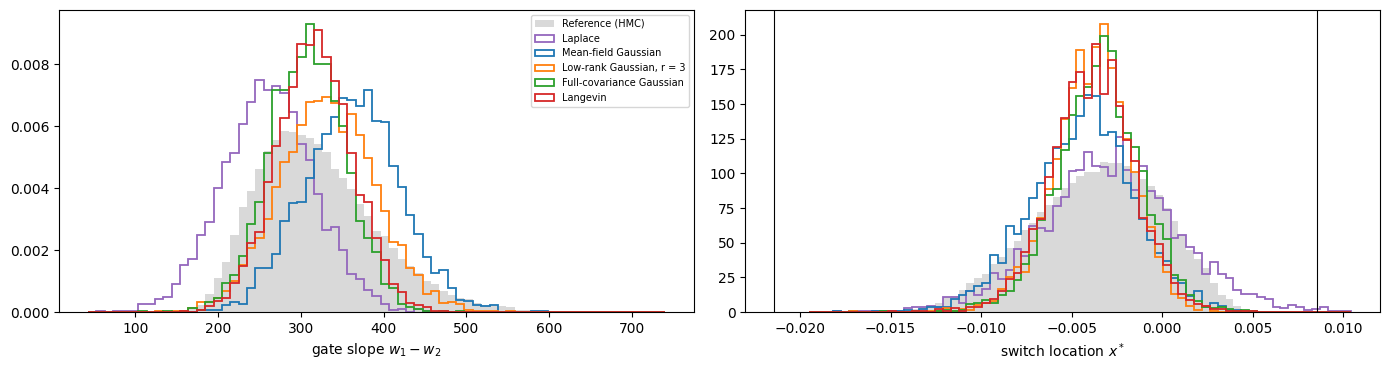

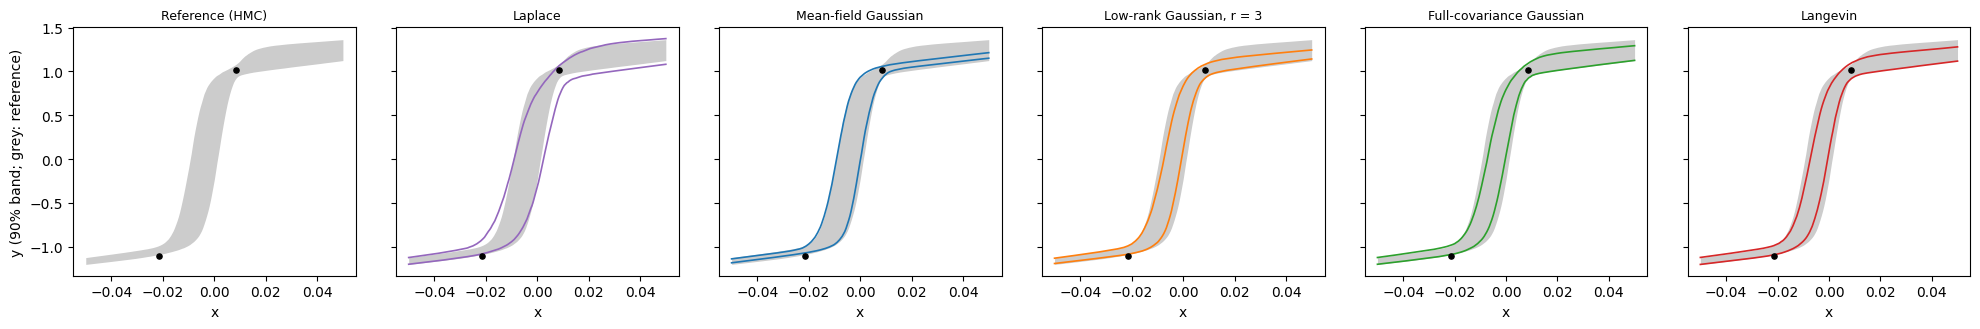

In [21]:
R_LOW = 3  # a low rank that is clearly too small, for contrast
torch.manual_seed(3)
with torch.no_grad():
    samples = {
        "exact": theta_exact[torch.randperm(theta_exact.shape[0])[:4000]],
        "laplace": theta_laplace[:4000],
        "iid": gauss[0]["group"].variational_distribution().sample((4000,)),
        "lowrank": gauss[R_LOW]["group"].variational_distribution().sample((4000,)),
        "full": gauss[D]["group"].variational_distribution().sample((4000,)),
        "langevin": langevin[SHOW]["theta"],
    }
label = dict(LABELS, lowrank=f"Low-rank Gaussian, r = {R_LOW}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, fn, xlabel in [(axes[0], gate_slope, "gate slope $w_1 - w_2$"), (axes[1], switch_location, "switch location $x^*$")]:
    ref_vals = fn(theta_exact)  # all HMC draws, for a smooth reference histogram
    lo, hi = torch.quantile(ref_vals, torch.tensor([0.001, 0.999])).tolist()
    lo, hi = lo - 0.3 * (hi - lo), hi + 0.3 * (hi - lo)
    bins = np.linspace(lo, hi, 70)
    ax.hist(ref_vals.numpy(), bins=bins, density=True, color="0.85", label=label["exact"])
    for kind in ["laplace", "iid", "lowrank", "full", "langevin"]:
        ax.hist(fn(samples[kind]).numpy(), bins=bins, density=True, histtype="step", lw=1.3,
                color=COLORS[kind], label=label[kind])
    ax.set_xlabel(xlabel)
axes[1].axvline(GAP[0], color="k", lw=0.8)
axes[1].axvline(GAP[1], color="k", lw=0.8)
axes[0].legend(fontsize=7)
plt.tight_layout()

x_zoom = torch.linspace(-0.05, 0.05, 201)[:, None]
kinds = ["exact", "laplace", "iid", "lowrank", "full", "langevin"]
fig, axes = plt.subplots(1, len(kinds), figsize=(20, 3.4), sharey=True)
with torch.no_grad():
    f_ref = surrogate(x_zoom, samples["exact"][:2000])[..., 0]
    band_ref = torch.quantile(f_ref, torch.tensor([0.05, 0.95]), dim=0)
    for ax, kind in zip(axes, kinds):
        f_k = surrogate(x_zoom, samples[kind][:2000])[..., 0]
        band = torch.quantile(f_k, torch.tensor([0.05, 0.95]), dim=0)
        ax.fill_between(x_zoom[:, 0], band_ref[0], band_ref[1], color="0.8", lw=0)
        if kind != "exact":
            ax.plot(x_zoom[:, 0], band[0], color=COLORS[kind], lw=1.2)
            ax.plot(x_zoom[:, 0], band[1], color=COLORS[kind], lw=1.2)
        near = x_train[:, 0].abs() < 0.05
        ax.scatter(x_train[near, 0], y_train[near, 0], color="k", s=14, zorder=5)
        ax.set_title(label[kind], fontsize=9)
        ax.set_xlabel("x")
axes[0].set_ylabel("y (90% band; grey: reference)")
plt.tight_layout()

The spread of the gate quantities, as standard deviations relative to the
reference:

In [22]:
sd_ref = gate_slope(theta_exact).std().item(), switch_location(theta_exact).std().item()
print(f"{'':28s} {'sd(slope) / ref':>16s} {'sd(x*) / ref':>14s}")
for kind in ["laplace", "iid", "lowrank", "full", "langevin"]:
    th = samples[kind]
    print(f"{label[kind]:28s} {gate_slope(th).std().item() / sd_ref[0]:16.2f} "
          f"{switch_location(th).std().item() / sd_ref[1]:14.2f}")

                              sd(slope) / ref   sd(x*) / ref
Laplace                                  0.76           1.13
Mean-field Gaussian                      0.80           0.82
Low-rank Gaussian, r = 3                 0.80           0.61
Full-covariance Gaussian                 0.63           0.67
Langevin                                 0.63           0.65


**The variational fits are too narrow in the gate.** The full Gaussian and
Langevin put the gate slope in the right place, but they underestimate the
spread of both gate quantities, at about two thirds of the reference, and
so the width of the predictive band at the jump. This is the usual behaviour of the reverse KL divergence that the
ELBO minimizes: it penalizes mass where the posterior has none much more
than it penalizes missing mass, so the fit prefers to be too narrow. The
Laplace approximation sits at the wrong place on the slope ridge instead,
and is too wide in the switch location.
Away from the jump, all approximations agree with the reference.

In [23]:
print(f"{'':32s} {'KL(q || p) [nats]':>20s}")
print(f"{LABELS['laplace']:32s} {kl_laplace:20.3f}")
print(f"{LABELS['iid']:32s} {kl_iid:20.3f}")
for r in range(1, D):
    print(f"{'Low-rank Gaussian, r = ' + str(r):32s} {gauss[r]['kl']:20.3f}")
print(f"{LABELS['full']:32s} {kl_full:20.3f}")
print(f"{LABELS['langevin']:32s} {kl_lang.min(1).mean():9.3f} to {kl_lang.max(1).mean():.3f}   ({len(SEEDS)} seeds)")

                                    KL(q || p) [nats]
Laplace                                         5.014
Mean-field Gaussian                            14.580
Low-rank Gaussian, r = 1                       10.065
Low-rank Gaussian, r = 2                        6.355
Low-rank Gaussian, r = 3                        2.708
Low-rank Gaussian, r = 4                        1.846
Low-rank Gaussian, r = 5                        1.260
Low-rank Gaussian, r = 6                        0.660
Low-rank Gaussian, r = 7                        0.654
Low-rank Gaussian, r = 8                        0.658
Low-rank Gaussian, r = 9                        0.657
Low-rank Gaussian, r = 10                       0.654
Low-rank Gaussian, r = 11                       0.658
Full-covariance Gaussian                        0.552
Langevin                             0.644 to 0.845   (3 seeds)
